In [ ]:
!pip install -q datasets gensim transformers accelerate beautifulsoup4 xgboost

# Library

In [ ]:
import re
import html
import random
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import torch

from bs4 import BeautifulSoup
from datasets import load_dataset
from gensim.models import Word2Vec

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)
from sklearn.feature_extraction.text import TfidfVectorizer
from gensim.models import Word2Vec
from transformers import AutoTokenizer, AutoModel

In [ ]:
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

In [ ]:
Device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print("Device",Device)

Device cuda


# Data Load and Exploration

In [ ]:


imdb = load_dataset("stanfordnlp/imdb")

print(imdb)

README.md:   0%|          | 0.00/7.81k [00:00<?, ?B/s]

plain_text/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 21.0MB            

plain_text/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

plain_text/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 20.5MB            

plain_text/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

plain_text/unsupervised-00000-of-00001.p(…): reconstructing file:   0%|          |  0.00B / 42.0MB            

plain_text/unsupervised-00000-of-00001.p(…): downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/25000 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/25000 [00:00<?, ? examples/s]

Generating unsupervised split:   0%|          | 0/50000 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['text', 'label'],
        num_rows: 25000
    })
    test: Dataset({
        features: ['text', 'label'],
        num_rows: 25000
    })
    unsupervised: Dataset({
        features: ['text', 'label'],
        num_rows: 50000
    })
})


In [ ]:
train_texts = imdb["train"]["text"]
train_labels = np.array(imdb["train"]["label"])

test_texts = imdb["test"]["text"]
test_labels = np.array(imdb["test"]["label"])

print("Training Samples:", len(train_texts))
print("Testing Samples:", len(test_texts))

Training Samples: 25000
Testing Samples: 25000


In [ ]:
train_texts[5]

"I would put this at the top of my list of films in the category of unwatchable trash! There are films that are bad, but the worst kind are the ones that are unwatchable but you are suppose to like them because they are supposed to be good for you! The sex sequences, so shocking in its day, couldn't even arouse a rabbit. The so called controversial politics is strictly high school sophomore amateur night Marxism. The film is self-consciously arty in the worst sense of the term. The photography is in a harsh grainy black and white. Some scenes are out of focus or taken from the wrong angle. Even the sound is bad! And some people call this art?<br /><br />"

In [ ]:
for i in range(5):
  print(train_texts[i])
  print("Sentiment:",
        "Postivie" if train_labels[i] == 1 else 'Negative'
        )

I rented I AM CURIOUS-YELLOW from my video store because of all the controversy that surrounded it when it was first released in 1967. I also heard that at first it was seized by U.S. customs if it ever tried to enter this country, therefore being a fan of films considered "controversial" I really had to see this for myself.<br /><br />The plot is centered around a young Swedish drama student named Lena who wants to learn everything she can about life. In particular she wants to focus her attentions to making some sort of documentary on what the average Swede thought about certain political issues such as the Vietnam War and race issues in the United States. In between asking politicians and ordinary denizens of Stockholm about their opinions on politics, she has sex with her drama teacher, classmates, and married men.<br /><br />What kills me about I AM CURIOUS-YELLOW is that 40 years ago, this was considered pornographic. Really, the sex and nudity scenes are few and far between, eve

0    12500
1    12500
Name: count, dtype: int64


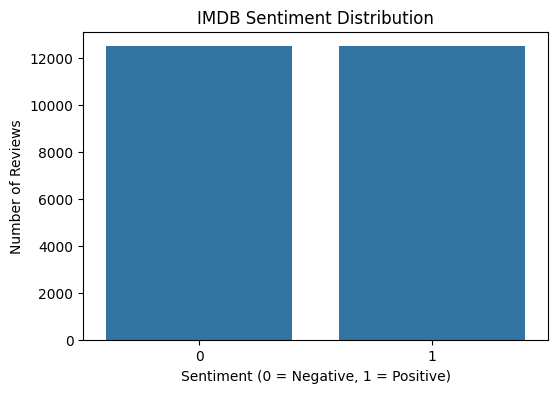

In [ ]:
label_counts = pd.Series(train_labels).value_counts()

print(label_counts)

plt.figure(figsize=(6, 4))

sns.countplot(x=train_labels)

plt.title("IMDB Sentiment Distribution")
plt.xlabel("Sentiment (0 = Negative, 1 = Positive)")
plt.ylabel("Number of Reviews")

plt.show()

# Preprocessing

In [ ]:
def clean_text(text):
    text = html.unescape(text)
    text = BeautifulSoup(text, "html.parser").get_text()
    text = text.lower()
    text = re.sub(r"[^a-z0-9\s']", " ", text)
    text = re.sub(r"\s+", " ", text).strip()

    return text

In [ ]:
start_time = time.time()

clean_train_texts = [
    clean_text(text)
    for text in train_texts
]

clean_test_texts = [
    clean_text(text)
    for text in test_texts
]

print("Preprocessing Completed!")

print(
    "Time Taken:",
    round(time.time() - start_time, 2),
    "seconds"
)

Preprocessing Completed!
Time Taken: 17.87 seconds


In [ ]:
print("Original Review:")
print(train_texts[0][:500])

print("\nCleaned Review:")
print(clean_train_texts[0][:500])

Original Review:
I rented I AM CURIOUS-YELLOW from my video store because of all the controversy that surrounded it when it was first released in 1967. I also heard that at first it was seized by U.S. customs if it ever tried to enter this country, therefore being a fan of films considered "controversial" I really had to see this for myself.<br /><br />The plot is centered around a young Swedish drama student named Lena who wants to learn everything she can about life. In particular she wants to focus her attent

Cleaned Review:
i rented i am curious yellow from my video store because of all the controversy that surrounded it when it was first released in 1967 i also heard that at first it was seized by u s customs if it ever tried to enter this country therefore being a fan of films considered controversial i really had to see this for myself the plot is centered around a young swedish drama student named lena who wants to learn everything she can about life in particular she wants to

# Train Test Validation

In [ ]:
X_train, X_val, y_train, y_val = train_test_split(
    clean_train_texts,
    train_labels,
    test_size=0.20,
    random_state=SEED,
    stratify=train_labels
)

X_test = clean_test_texts
y_test = test_labels

print("Training Samples:", len(X_train))
print("Validation Samples:", len(X_val))
print("Testing Samples:", len(X_test))

print("\nTraining Labels:")
print(pd.Series(y_train).value_counts())

print("\nValidation Labels:")
print(pd.Series(y_val).value_counts())

print("\nTesting Labels:")
print(pd.Series(y_test).value_counts())

Training Samples: 20000
Validation Samples: 5000
Testing Samples: 25000

Training Labels:
1    10000
0    10000
Name: count, dtype: int64

Validation Labels:
1    2500
0    2500
Name: count, dtype: int64

Testing Labels:
0    12500
1    12500
Name: count, dtype: int64


# Evaluation Helper Function

In [ ]:
all_results = []
all_models = {}

def evaluate_model(
    model,
    model_name,
    feature_name,
    X_train_data,
    X_val_data,
    X_test_data,
    feature_time
):

    # Training
    start_time = time.time()

    model.fit(X_train_data, y_train)

    training_time = time.time() - start_time

    # Validation prediction
    start_time = time.time()

    val_pred = model.predict(X_val_data)

    val_prediction_time = time.time() - start_time

    val_accuracy = accuracy_score(y_val, val_pred)
    val_f1 = f1_score(y_val, val_pred)

    # Test prediction
    start_time = time.time()

    test_pred = model.predict(X_test_data)

    prediction_time = time.time() - start_time

    accuracy = accuracy_score(y_test, test_pred)
    precision = precision_score(y_test, test_pred)
    recall = recall_score(y_test, test_pred)
    f1 = f1_score(y_test, test_pred)

    total_pipeline_time = (
        feature_time + training_time + prediction_time
    )

    full_name = feature_name + " + " + model_name

    result = {
        "Feature Extraction": feature_name,
        "Classifier": model_name,
        "Model": full_name,
        "Validation Accuracy": val_accuracy,
        "Validation F1": val_f1,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1 Score": f1,
        "Feature Extraction Time (sec)": feature_time,
        "Training Time (sec)": training_time,
        "Prediction Time (sec)": prediction_time,
        "Total Pipeline Time (sec)": total_pipeline_time
    }

    all_results.append(result)

    all_models[full_name] = {
        "model": model,
        "predictions": test_pred,
        "validation_predictions": val_pred
    }

    print("\n", "=" * 60)
    print(full_name)
    print("=" * 60)

    print("Validation Accuracy:", round(val_accuracy, 4))
    print("Validation F1 Score:", round(val_f1, 4))

    print("\nTest Results:")
    print("Accuracy:", round(accuracy, 4))
    print("Precision:", round(precision, 4))
    print("Recall:", round(recall, 4))
    print("F1 Score:", round(f1, 4))

    print("\nTraining Time:", round(training_time, 2), "seconds")
    print("Prediction Time:", round(prediction_time, 2), "seconds")

    print("\nClassification Report:")
    print(classification_report(y_test, test_pred))

    return model

# TF-IDF

In [ ]:
tfidf = TfidfVectorizer(max_features=30000, ngram_range=(1,2),min_df=2,max_df=0.95,sublinear_tf=True)

In [ ]:
start_time = time.time()

tfidf = TfidfVectorizer(
    max_features=30000,
    ngram_range=(1, 2),
    min_df=2,
    max_df=0.95,
    sublinear_tf=True
)

X_train_tfidf = tfidf.fit_transform(X_train)

X_val_tfidf = tfidf.transform(X_val)

X_test_tfidf = tfidf.transform(X_test)

tfidf_extraction_time = time.time() - start_time

print("TF-IDF Feature Extraction Completed!")

print("Training Shape:", X_train_tfidf.shape)
print("Validation Shape:", X_val_tfidf.shape)
print("Testing Shape:", X_test_tfidf.shape)

print("Feature Extraction Time:",
      round(tfidf_extraction_time, 2), "seconds")

TF-IDF Feature Extraction Completed!
Training Shape: (20000, 30000)
Validation Shape: (5000, 30000)
Testing Shape: (25000, 30000)
Feature Extraction Time: 27.51 seconds


In [ ]:
print("Total Vocabulary:", len(tfidf.vocabulary_))

print("\nSample Words:")

print(list(tfidf.vocabulary_.keys())[:20])

Total Vocabulary: 30000

Sample Words:
['have', 'always', 'been', 'huge', 'james', 'bond', 'fanatic', 'seen', 'almost', 'all', 'of', 'films', 'except', 'for', 'die', 'another', 'day', 'world', 'is', 'not']


## Logistic Regression Model

In [ ]:
tfidf_lr = LogisticRegression(
    max_iter=1000,
    C=2.0,
    random_state=SEED
)

tfidf_lr = evaluate_model(
    tfidf_lr,
    "Logistic Regression",
    "TF-IDF",
    X_train_tfidf,
    X_val_tfidf,
    X_test_tfidf,
    tfidf_extraction_time
)


TF-IDF + Logistic Regression
Validation Accuracy: 0.9032
Validation F1 Score: 0.9041

Test Results:
Accuracy: 0.9002
Precision: 0.8978
Recall: 0.9034
F1 Score: 0.9006

Training Time: 1.06 seconds
Prediction Time: 0.05 seconds

Classification Report:
              precision    recall  f1-score   support

           0       0.90      0.90      0.90     12500
           1       0.90      0.90      0.90     12500

    accuracy                           0.90     25000
   macro avg       0.90      0.90      0.90     25000
weighted avg       0.90      0.90      0.90     25000



## Random Forest

In [ ]:
tfidf_rf = RandomForestClassifier(
    n_estimators=150,
    max_features="sqrt",
    min_samples_leaf=2,
    n_jobs=-1,
    random_state=SEED
)

tfidf_rf = evaluate_model(
    tfidf_rf,
    "Random Forest",
    "TF-IDF",
    X_train_tfidf,
    X_val_tfidf,
    X_test_tfidf,
    tfidf_extraction_time
)


TF-IDF + Random Forest
Validation Accuracy: 0.8562
Validation F1 Score: 0.8567

Test Results:
Accuracy: 0.8512
Precision: 0.8496
Recall: 0.8535
F1 Score: 0.8515

Training Time: 67.82 seconds
Prediction Time: 2.71 seconds

Classification Report:
              precision    recall  f1-score   support

           0       0.85      0.85      0.85     12500
           1       0.85      0.85      0.85     12500

    accuracy                           0.85     25000
   macro avg       0.85      0.85      0.85     25000
weighted avg       0.85      0.85      0.85     25000



## XGBoost

In [ ]:
tfidf_xgb = XGBClassifier(
    n_estimators=200,
    max_depth=6,
    learning_rate=0.1,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="binary:logistic",
    eval_metric="logloss",
    tree_method="hist",
    n_jobs=-1,
    random_state=SEED
)

tfidf_xgb = evaluate_model(
    tfidf_xgb,
    "XGBoost",
    "TF-IDF",
    X_train_tfidf,
    X_val_tfidf,
    X_test_tfidf,
    tfidf_extraction_time
)


TF-IDF + XGBoost
Validation Accuracy: 0.8614
Validation F1 Score: 0.8648

Test Results:
Accuracy: 0.8557
Precision: 0.8429
Recall: 0.8745
F1 Score: 0.8584

Training Time: 467.09 seconds
Prediction Time: 0.33 seconds

Classification Report:
              precision    recall  f1-score   support

           0       0.87      0.84      0.85     12500
           1       0.84      0.87      0.86     12500

    accuracy                           0.86     25000
   macro avg       0.86      0.86      0.86     25000
weighted avg       0.86      0.86      0.86     25000



## KNN

In [ ]:
tfidf_knn = KNeighborsClassifier(
    n_neighbors=5,
    weights="distance",
    metric="cosine",
    algorithm="brute",
    n_jobs=-1
)

tfidf_knn = evaluate_model(
    tfidf_knn,
    "KNN",
    "TF-IDF",
    X_train_tfidf,
    X_val_tfidf,
    X_test_tfidf,
    tfidf_extraction_time
)


TF-IDF + KNN
Validation Accuracy: 0.8198
Validation F1 Score: 0.8266

Test Results:
Accuracy: 0.7513
Precision: 0.7577
Recall: 0.7389
F1 Score: 0.7482

Training Time: 0.02 seconds
Prediction Time: 48.77 seconds

Classification Report:
              precision    recall  f1-score   support

           0       0.75      0.76      0.75     12500
           1       0.76      0.74      0.75     12500

    accuracy                           0.75     25000
   macro avg       0.75      0.75      0.75     25000
weighted avg       0.75      0.75      0.75     25000



# Word2Vec

## Feature Extraction

In [ ]:


start_time = time.time()

w2v_model = Word2Vec(
    sentences=X_train_tokens,
    vector_size=100,
    window=5,
    min_count=2,
    workers=4,
    sg=1,
    epochs=10
)

w2v_training_time = time.time() - start_time

print("Word2Vec Model Training Completed!")

print("Vocabulary Size:", len(w2v_model.wv))
print("Vector Size:", w2v_model.vector_size)

print("Word2Vec Training Time:",
      round(w2v_training_time, 2), "seconds")

Word2Vec Model Training Completed!
Vocabulary Size: 46970
Vector Size: 100
Word2Vec Training Time: 221.81 seconds


In [ ]:
def document_vector(tokens, model):

    vectors = [
        model.wv[word]
        for word in tokens
        if word in model.wv
    ]

    if len(vectors) == 0:
        return np.zeros(model.vector_size)

    return np.mean(vectors, axis=0)

In [ ]:
start_time = time.time()

X_train_w2v = np.array([
    document_vector(tokens, w2v_model)
    for tokens in X_train_tokens
])

X_val_w2v = np.array([
    document_vector(tokens, w2v_model)
    for tokens in X_val_tokens
])

X_test_w2v = np.array([
    document_vector(tokens, w2v_model)
    for tokens in X_test_tokens
])

w2v_embedding_time = time.time() - start_time

w2v_total_feature_time = (
    w2v_training_time + w2v_embedding_time
)

print("Word2Vec Embeddings Generated!")

print("Training Shape:", X_train_w2v.shape)
print("Validation Shape:", X_val_w2v.shape)
print("Testing Shape:", X_test_w2v.shape)

print("Embedding Generation Time:",
      round(w2v_embedding_time, 2), "seconds")

print("Total Word2Vec Feature Time:",
      round(w2v_total_feature_time, 2), "seconds")

Word2Vec Embeddings Generated!
Training Shape: (20000, 100)
Validation Shape: (5000, 100)
Testing Shape: (25000, 100)
Embedding Generation Time: 20.04 seconds
Total Word2Vec Feature Time: 241.85 seconds


## Logistic Regression

In [ ]:
w2v_lr = LogisticRegression(
    max_iter=1000,
    C=1.0,
    random_state=SEED
)

w2v_lr = evaluate_model(
    w2v_lr,
    "Logistic Regression",
    "Word2Vec",
    X_train_w2v,
    X_val_w2v,
    X_test_w2v,
    w2v_total_feature_time
)


Word2Vec + Logistic Regression
Validation Accuracy: 0.8684
Validation F1 Score: 0.8691

Test Results:
Accuracy: 0.8536
Precision: 0.8607
Recall: 0.8436
F1 Score: 0.8521

Training Time: 0.37 seconds
Prediction Time: 0.01 seconds

Classification Report:
              precision    recall  f1-score   support

           0       0.85      0.86      0.86     12500
           1       0.86      0.84      0.85     12500

    accuracy                           0.85     25000
   macro avg       0.85      0.85      0.85     25000
weighted avg       0.85      0.85      0.85     25000



## Random forest

In [ ]:
w2v_rf = RandomForestClassifier(
    n_estimators=150,
    max_features="sqrt",
    min_samples_leaf=2,
    n_jobs=-1,
    random_state=SEED
)

w2v_rf = evaluate_model(
    w2v_rf,
    "Random Forest",
    "Word2Vec",
    X_train_w2v,
    X_val_w2v,
    X_test_w2v,
    w2v_total_feature_time
)


Word2Vec + Random Forest
Validation Accuracy: 0.8356
Validation F1 Score: 0.8367

Test Results:
Accuracy: 0.8262
Precision: 0.8337
Recall: 0.815
F1 Score: 0.8243

Training Time: 37.19 seconds
Prediction Time: 0.34 seconds

Classification Report:
              precision    recall  f1-score   support

           0       0.82      0.84      0.83     12500
           1       0.83      0.82      0.82     12500

    accuracy                           0.83     25000
   macro avg       0.83      0.83      0.83     25000
weighted avg       0.83      0.83      0.83     25000



## XGBoost

In [ ]:
w2v_xgb = XGBClassifier(
    n_estimators=200,
    max_depth=6,
    learning_rate=0.1,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="binary:logistic",
    eval_metric="logloss",
    tree_method="hist",
    n_jobs=-1,
    random_state=SEED
)

w2v_xgb = evaluate_model(
    w2v_xgb,
    "XGBoost",
    "Word2Vec",
    X_train_w2v,
    X_val_w2v,
    X_test_w2v,
    w2v_total_feature_time
)


Word2Vec + XGBoost
Validation Accuracy: 0.866
Validation F1 Score: 0.8665

Test Results:
Accuracy: 0.851
Precision: 0.8594
Recall: 0.8394
F1 Score: 0.8492

Training Time: 6.94 seconds
Prediction Time: 0.1 seconds

Classification Report:
              precision    recall  f1-score   support

           0       0.84      0.86      0.85     12500
           1       0.86      0.84      0.85     12500

    accuracy                           0.85     25000
   macro avg       0.85      0.85      0.85     25000
weighted avg       0.85      0.85      0.85     25000



## KNN

In [ ]:
w2v_knn = KNeighborsClassifier(
    n_neighbors=5,
    weights="distance",
    metric="cosine",
    algorithm="brute",
    n_jobs=-1
)

w2v_knn = evaluate_model(
    w2v_knn,
    "KNN",
    "Word2Vec",
    X_train_w2v,
    X_val_w2v,
    X_test_w2v,
    w2v_total_feature_time
)


Word2Vec + KNN
Validation Accuracy: 0.8032
Validation F1 Score: 0.7971

Test Results:
Accuracy: 0.7754
Precision: 0.8128
Recall: 0.7157
F1 Score: 0.7612

Training Time: 0.0 seconds
Prediction Time: 7.07 seconds

Classification Report:
              precision    recall  f1-score   support

           0       0.75      0.84      0.79     12500
           1       0.81      0.72      0.76     12500

    accuracy                           0.78     25000
   macro avg       0.78      0.78      0.77     25000
weighted avg       0.78      0.78      0.77     25000



# Bert Embedding

## Feature Extraction

In [ ]:
MODEL_NAME = "bert-base-uncased"

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

bert_model = AutoModel.from_pretrained(MODEL_NAME)

bert_model.to(device)

bert_model.eval()

print("BERT Model Loaded Successfully!")
print("Device:", device)

config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  440MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: bert-base-uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


BERT Model Loaded Successfully!
Device: cuda


In [ ]:
def extract_bert_embeddings(
    texts,
    batch_size=32,
    max_length=256
):

    all_embeddings = []

    for start in range(0, len(texts), batch_size):

        batch_texts = texts[start:start + batch_size]

        encoded = tokenizer(
            batch_texts,
            padding=True,
            truncation=True,
            max_length=max_length,
            return_tensors="pt"
        )

        encoded = {
            key: value.to(device)
            for key, value in encoded.items()
        }

        with torch.no_grad():

            outputs = bert_model(**encoded)

            embeddings = outputs.last_hidden_state[:, 0, :]

        all_embeddings.append(
            embeddings.cpu().numpy()
        )

    return np.vstack(all_embeddings)

In [ ]:
start_time = time.time()

X_train_bert = extract_bert_embeddings(X_train)

X_val_bert = extract_bert_embeddings(X_val)

X_test_bert = extract_bert_embeddings(X_test)

bert_extraction_time = time.time() - start_time

print("BERT Embedding Extraction Completed!")

print("Training Shape:", X_train_bert.shape)
print("Validation Shape:", X_val_bert.shape)
print("Testing Shape:", X_test_bert.shape)

print("BERT Feature Extraction Time:",
      round(bert_extraction_time, 2), "seconds")

BERT Embedding Extraction Completed!
Training Shape: (20000, 768)
Validation Shape: (5000, 768)
Testing Shape: (25000, 768)
BERT Feature Extraction Time: 909.25 seconds


## Logistic Regression

In [ ]:
bert_lr = LogisticRegression(
    max_iter=1000,
    C=1.0,
    random_state=SEED
)

bert_lr = evaluate_model(
    bert_lr,
    "Logistic Regression",
    "BERT Embedding",
    X_train_bert,
    X_val_bert,
    X_test_bert,
    bert_extraction_time
)


BERT Embedding + Logistic Regression
Validation Accuracy: 0.8558
Validation F1 Score: 0.8552

Test Results:
Accuracy: 0.8471
Precision: 0.8536
Recall: 0.8379
F1 Score: 0.8457

Training Time: 8.79 seconds
Prediction Time: 0.1 seconds

Classification Report:
              precision    recall  f1-score   support

           0       0.84      0.86      0.85     12500
           1       0.85      0.84      0.85     12500

    accuracy                           0.85     25000
   macro avg       0.85      0.85      0.85     25000
weighted avg       0.85      0.85      0.85     25000



## Random Forest

In [ ]:
bert_rf = RandomForestClassifier(
    n_estimators=150,
    max_features="sqrt",
    min_samples_leaf=2,
    n_jobs=-1,
    random_state=SEED
)

bert_rf = evaluate_model(
    bert_rf,
    "Random Forest",
    "BERT Embedding",
    X_train_bert,
    X_val_bert,
    X_test_bert,
    bert_extraction_time
)


BERT Embedding + Random Forest
Validation Accuracy: 0.7956
Validation F1 Score: 0.8004

Test Results:
Accuracy: 0.8004
Precision: 0.7923
Recall: 0.8143
F1 Score: 0.8032

Training Time: 96.98 seconds
Prediction Time: 0.72 seconds

Classification Report:
              precision    recall  f1-score   support

           0       0.81      0.79      0.80     12500
           1       0.79      0.81      0.80     12500

    accuracy                           0.80     25000
   macro avg       0.80      0.80      0.80     25000
weighted avg       0.80      0.80      0.80     25000



## XGBoost

In [ ]:
bert_xgb = XGBClassifier(
    n_estimators=200,
    max_depth=6,
    learning_rate=0.1,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="binary:logistic",
    eval_metric="logloss",
    tree_method="hist",
    n_jobs=-1,
    random_state=SEED
)

bert_xgb = evaluate_model(
    bert_xgb,
    "XGBoost",
    "BERT Embedding",
    X_train_bert,
    X_val_bert,
    X_test_bert,
    bert_extraction_time
)


BERT Embedding + XGBoost
Validation Accuracy: 0.828
Validation F1 Score: 0.8289

Test Results:
Accuracy: 0.8285
Precision: 0.8288
Recall: 0.8281
F1 Score: 0.8284

Training Time: 63.8 seconds
Prediction Time: 0.19 seconds

Classification Report:
              precision    recall  f1-score   support

           0       0.83      0.83      0.83     12500
           1       0.83      0.83      0.83     12500

    accuracy                           0.83     25000
   macro avg       0.83      0.83      0.83     25000
weighted avg       0.83      0.83      0.83     25000



## KNN

In [ ]:
bert_knn = KNeighborsClassifier(
    n_neighbors=5,
    weights="distance",
    metric="cosine",
    algorithm="brute",
    n_jobs=-1
)

bert_knn = evaluate_model(
    bert_knn,
    "KNN",
    "BERT Embedding",
    X_train_bert,
    X_val_bert,
    X_test_bert,
    bert_extraction_time
)


BERT Embedding + KNN
Validation Accuracy: 0.7452
Validation F1 Score: 0.721

Test Results:
Accuracy: 0.7374
Precision: 0.8013
Recall: 0.6313
F1 Score: 0.7062

Training Time: 0.01 seconds
Prediction Time: 18.87 seconds

Classification Report:
              precision    recall  f1-score   support

           0       0.70      0.84      0.76     12500
           1       0.80      0.63      0.71     12500

    accuracy                           0.74     25000
   macro avg       0.75      0.74      0.73     25000
weighted avg       0.75      0.74      0.73     25000



# Comparison Table

## Compare validation performance

In [ ]:
validation_df = results_df.sort_values(
    by="Validation F1",
    ascending=False
).reset_index(drop=True)

print("MODEL RANKING BASED ON VALIDATION F1-SCORE")

display(
    validation_df[
        [
            "Feature Extraction",
            "Classifier",
            "Validation Accuracy",
            "Validation F1"
        ]
    ].round(4)
)

MODEL RANKING BASED ON VALIDATION F1-SCORE


,Feature Extraction,Classifier,Validation Accuracy,Validation F1
0,TF-IDF,Logistic Regression,0.9032,0.9041
1,Word2Vec,Logistic Regression,0.8684,0.8691
2,Word2Vec,XGBoost,0.8660,0.8665
3,TF-IDF,XGBoost,0.8614,0.8648
4,TF-IDF,Random Forest,0.8562,0.8567
5,BERT Embedding,Logistic Regression,0.8558,0.8552
6,Word2Vec,Random Forest,0.8356,0.8367
7,BERT Embedding,XGBoost,0.8280,0.8289
8,TF-IDF,KNN,0.8198,0.8266
9,BERT Embedding,Random Forest,0.7956,0.8004


## Compare models separately by feature extraction

In [ ]:
print("TF-IDF MODEL COMPARISON")

display(
    results_df[
        results_df["Feature Extraction"] == "TF-IDF"
    ].round(4)
)

print("\nWORD2VEC MODEL COMPARISON")

display(
    results_df[
        results_df["Feature Extraction"] == "Word2Vec"
    ].round(4)
)

print("\nBERT EMBEDDING MODEL COMPARISON")

display(
    results_df[
        results_df["Feature Extraction"] == "BERT Embedding"
    ].round(4)
)

TF-IDF MODEL COMPARISON


,Feature Extraction,Classifier,Model,Validation Accuracy,Validation F1,Accuracy,Precision,Recall,F1 Score,Feature Extraction Time (sec),Training Time (sec),Prediction Time (sec),Total Pipeline Time (sec)
0,TF-IDF,Logistic Regression,TF-IDF + Logistic Regression,0.9032,0.9041,0.9002,0.8978,0.9034,0.9006,27.5141,1.0593,0.0462,28.6196
1,TF-IDF,XGBoost,TF-IDF + XGBoost,0.8614,0.8648,0.8557,0.8429,0.8745,0.8584,27.5141,467.0903,0.3309,494.9352
3,TF-IDF,Random Forest,TF-IDF + Random Forest,0.8562,0.8567,0.8512,0.8496,0.8535,0.8515,27.5141,67.8229,2.7093,98.0462
10,TF-IDF,KNN,TF-IDF + KNN,0.8198,0.8266,0.7513,0.7577,0.7389,0.7482,27.5141,0.0173,48.7741,76.3054



WORD2VEC MODEL COMPARISON


,Feature Extraction,Classifier,Model,Validation Accuracy,Validation F1,Accuracy,Precision,Recall,F1 Score,Feature Extraction Time (sec),Training Time (sec),Prediction Time (sec),Total Pipeline Time (sec)
2,Word2Vec,Logistic Regression,Word2Vec + Logistic Regression,0.8684,0.8691,0.8536,0.8607,0.8436,0.8521,241.8502,0.3731,0.0150,242.2382
4,Word2Vec,XGBoost,Word2Vec + XGBoost,0.8660,0.8665,0.8510,0.8594,0.8394,0.8492,241.8502,6.9380,0.0952,248.8834
7,Word2Vec,Random Forest,Word2Vec + Random Forest,0.8356,0.8367,0.8262,0.8337,0.8150,0.8243,241.8502,37.1942,0.3398,279.3841
9,Word2Vec,KNN,Word2Vec + KNN,0.8032,0.7971,0.7754,0.8128,0.7157,0.7612,241.8502,0.0038,7.0717,248.9256



BERT EMBEDDING MODEL COMPARISON


,Feature Extraction,Classifier,Model,Validation Accuracy,Validation F1,Accuracy,Precision,Recall,F1 Score,Feature Extraction Time (sec),Training Time (sec),Prediction Time (sec),Total Pipeline Time (sec)
5,BERT Embedding,Logistic Regression,BERT Embedding + Logistic Regression,0.8558,0.8552,0.8471,0.8536,0.8379,0.8457,909.2457,8.7935,0.1042,918.1435
6,BERT Embedding,XGBoost,BERT Embedding + XGBoost,0.8280,0.8289,0.8285,0.8288,0.8281,0.8284,909.2457,63.8012,0.1885,973.2354
8,BERT Embedding,Random Forest,BERT Embedding + Random Forest,0.7956,0.8004,0.8004,0.7923,0.8143,0.8032,909.2457,96.9814,0.7180,1006.9451
11,BERT Embedding,KNN,BERT Embedding + KNN,0.7452,0.7210,0.7374,0.8013,0.6313,0.7062,909.2457,0.0088,18.8716,928.1262


## Precision Recall F1 Comparision

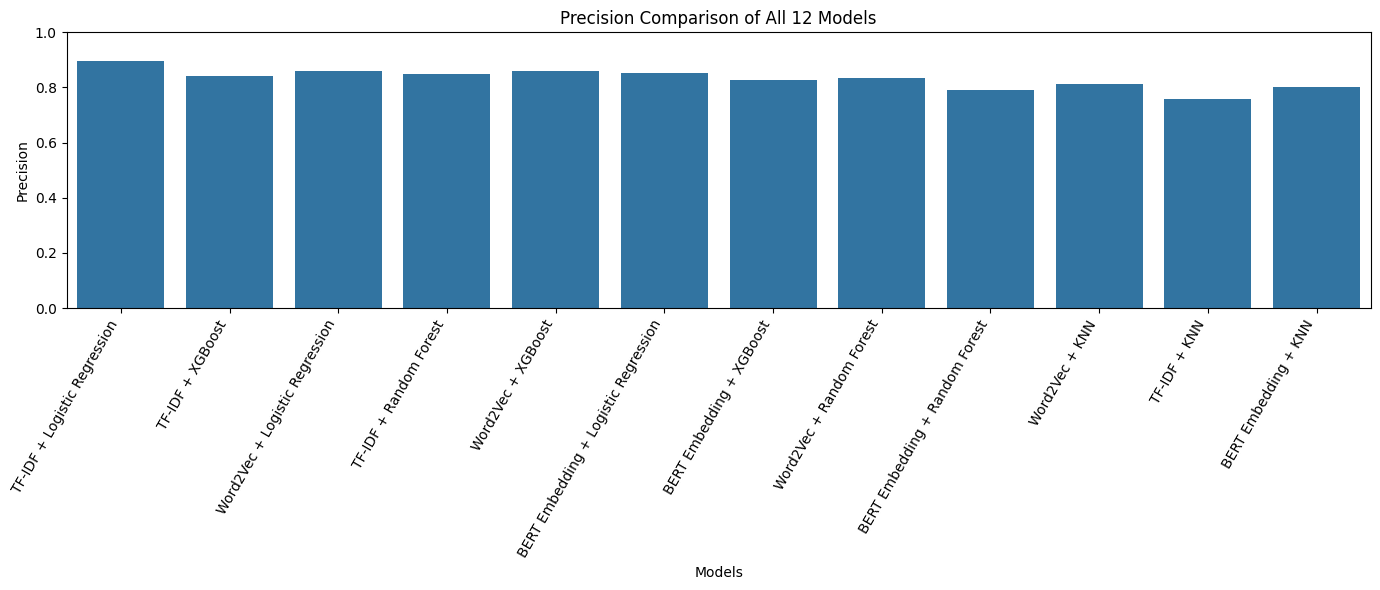

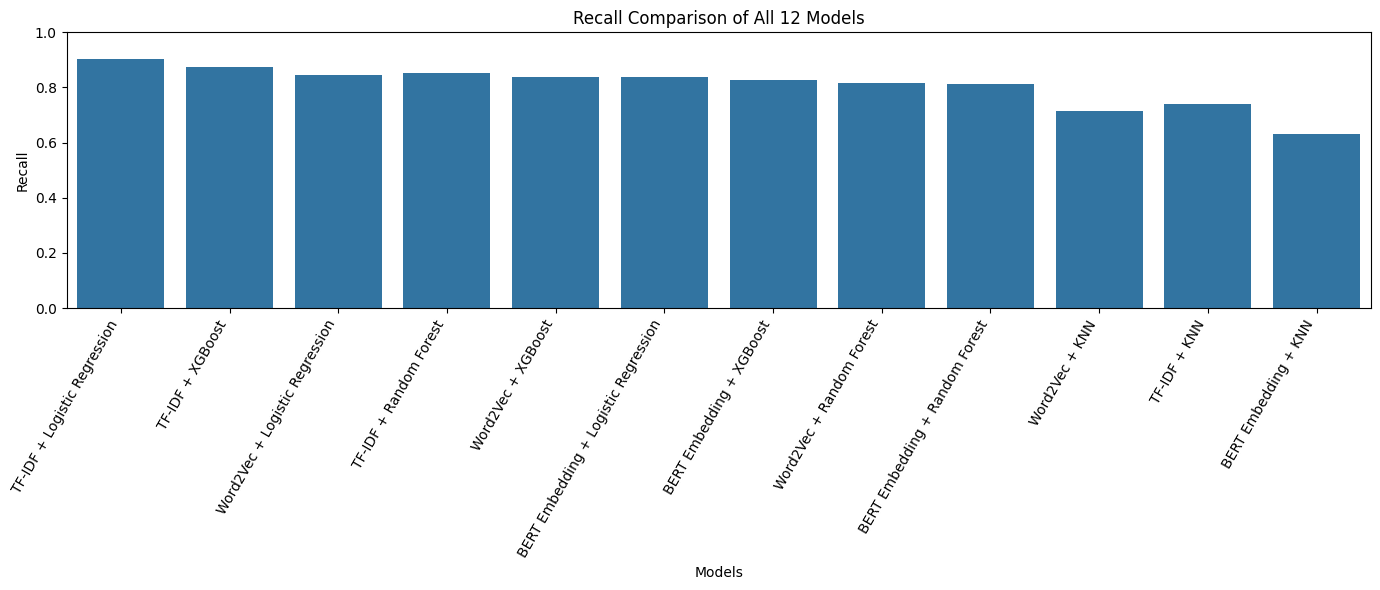

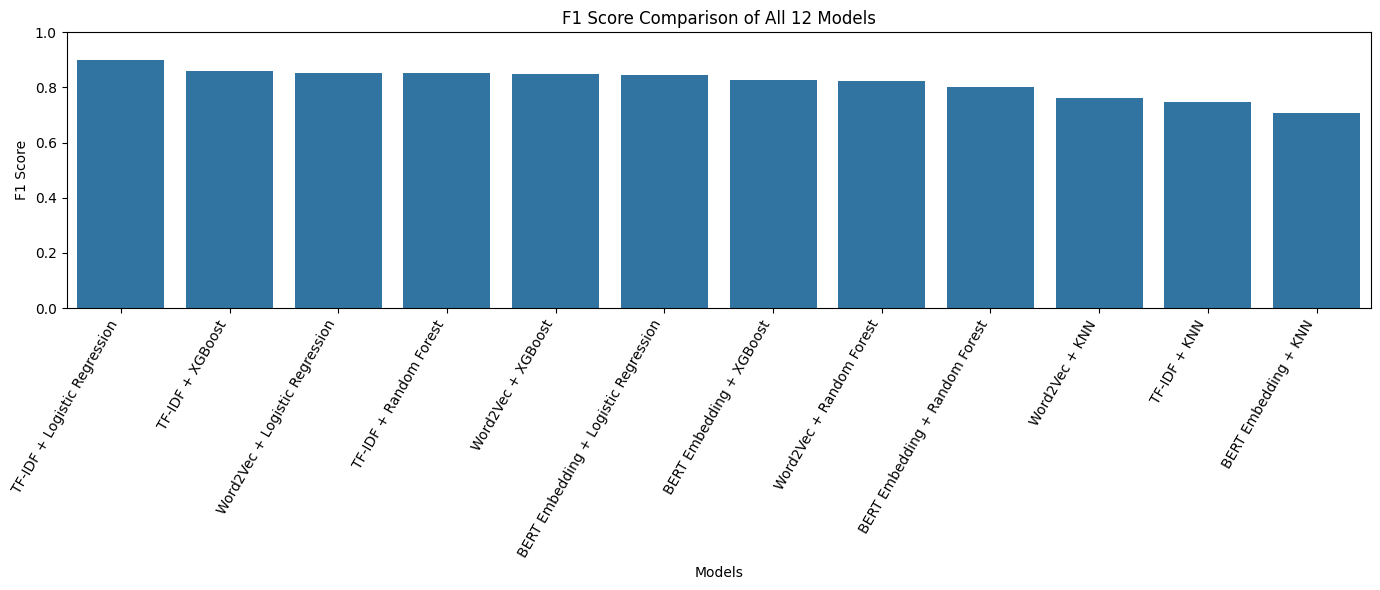

In [ ]:
metrics = ["Precision", "Recall", "F1 Score"]

for metric in metrics:

    plt.figure(figsize=(14, 6))

    sns.barplot(
        data=results_df,
        x="Model",
        y=metric
    )

    plt.title(f"{metric} Comparison of All 12 Models")
    plt.xlabel("Models")
    plt.ylabel(metric)
    plt.xticks(rotation=60, ha="right")
    plt.ylim(0, 1)

    plt.tight_layout()
    plt.show()

## Accuracy Heatmap

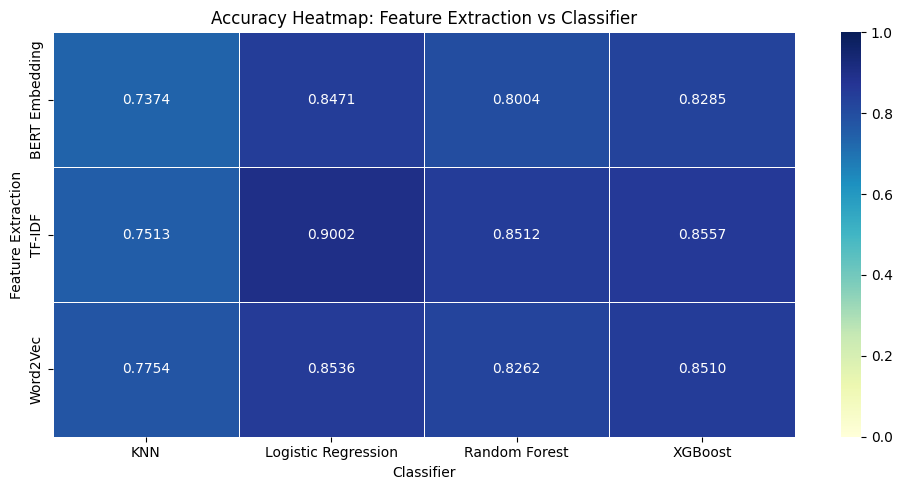

In [ ]:
accuracy_pivot = results_df.pivot(
    index="Feature Extraction",
    columns="Classifier",
    values="Accuracy"
)

plt.figure(figsize=(10, 5))

sns.heatmap(
    accuracy_pivot,
    annot=True,
    fmt=".4f",
    cmap="YlGnBu",
    linewidths=0.5,
    vmin=0,
    vmax=1
)

plt.title("Accuracy Heatmap: Feature Extraction vs Classifier")
plt.xlabel("Classifier")
plt.ylabel("Feature Extraction")

plt.tight_layout()
plt.show()

## F1 Score Heatmap

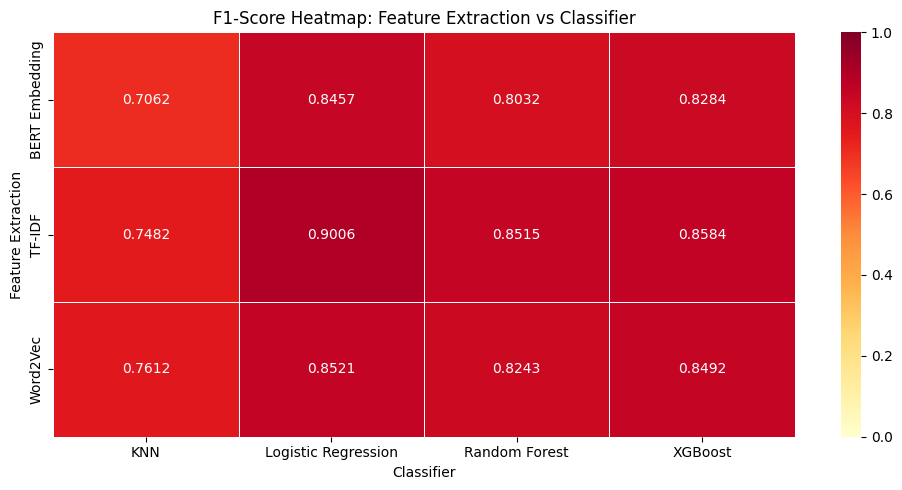

In [ ]:
f1_pivot = results_df.pivot(
    index="Feature Extraction",
    columns="Classifier",
    values="F1 Score"
)

plt.figure(figsize=(10, 5))

sns.heatmap(
    f1_pivot,
    annot=True,
    fmt=".4f",
    cmap="YlOrRd",
    linewidths=0.5,
    vmin=0,
    vmax=1
)

plt.title("F1-Score Heatmap: Feature Extraction vs Classifier")
plt.xlabel("Classifier")
plt.ylabel("Feature Extraction")

plt.tight_layout()
plt.show()

## Training Time Comparision

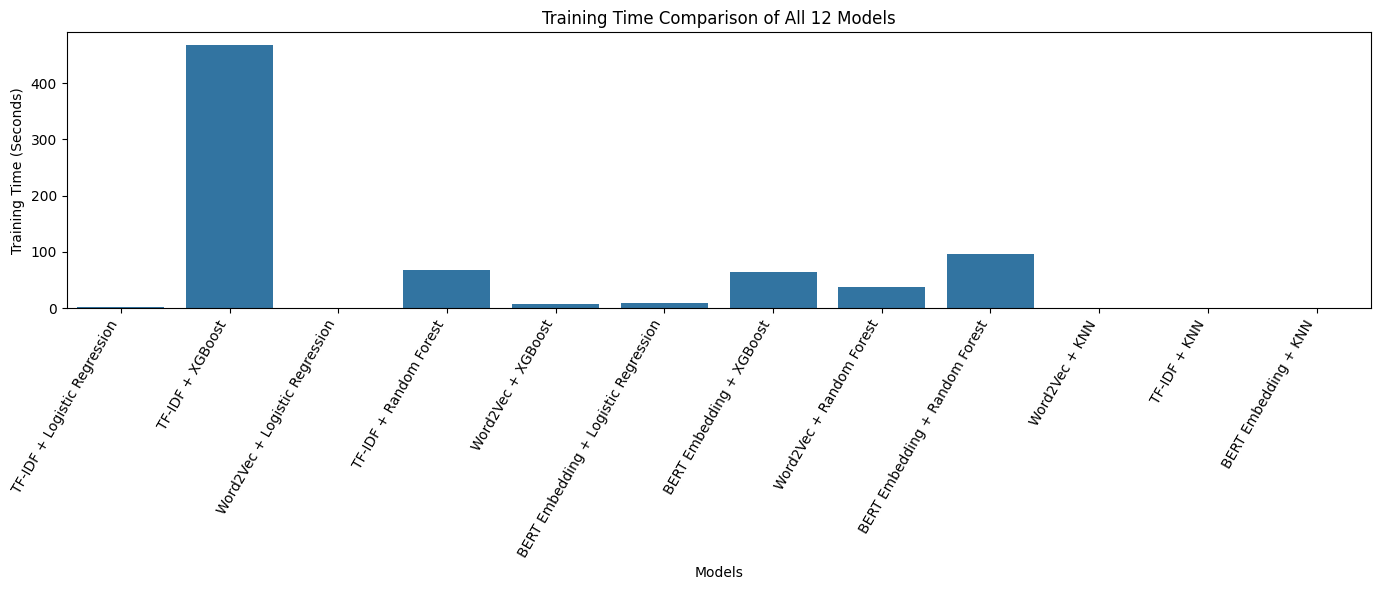

In [ ]:
plt.figure(figsize=(14, 6))

sns.barplot(
    data=results_df,
    x="Model",
    y="Training Time (sec)"
)

plt.title("Training Time Comparison of All 12 Models")
plt.xlabel("Models")
plt.ylabel("Training Time (Seconds)")
plt.xticks(rotation=60, ha="right")

plt.tight_layout()
plt.show()

## Average performance by feature extraction

AVERAGE PERFORMANCE BY FEATURE EXTRACTION


,Feature Extraction,Accuracy,Precision,Recall,F1 Score
0,BERT Embedding,0.8034,0.8190,0.7779,0.7959
1,TF-IDF,0.8396,0.8370,0.8426,0.8397
2,Word2Vec,0.8266,0.8417,0.8034,0.8217


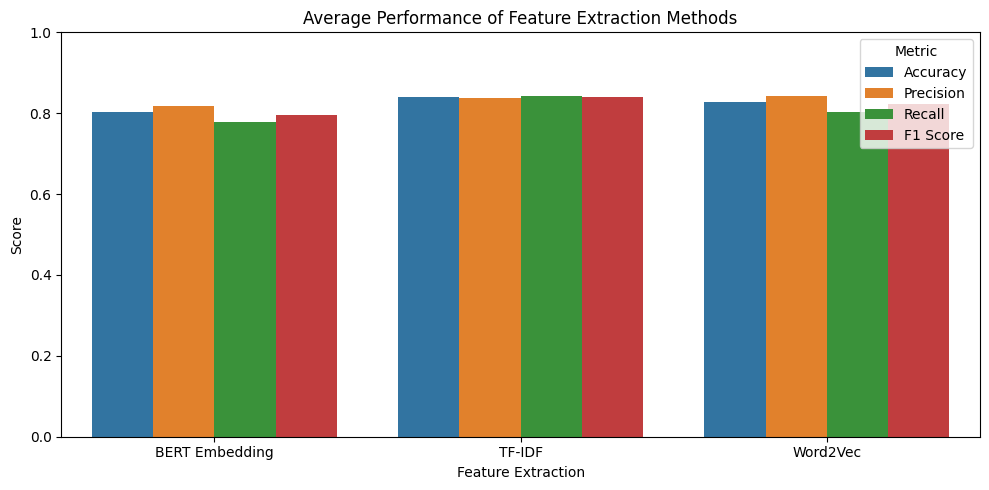

In [ ]:
feature_comparison = results_df.groupby(
    "Feature Extraction"
)[
    ["Accuracy", "Precision", "Recall", "F1 Score"]
].mean().reset_index()

print("AVERAGE PERFORMANCE BY FEATURE EXTRACTION")

display(feature_comparison.round(4))

plt.figure(figsize=(10, 5))

feature_plot = feature_comparison.melt(
    id_vars="Feature Extraction",
    var_name="Metric",
    value_name="Score"
)

sns.barplot(
    data=feature_plot,
    x="Feature Extraction",
    y="Score",
    hue="Metric"
)

plt.title("Average Performance of Feature Extraction Methods")
plt.ylim(0, 1)
plt.tight_layout()
plt.show()

## Average performance by classifier

AVERAGE PERFORMANCE BY CLASSIFIER


,Classifier,Accuracy,Precision,Recall,F1 Score
0,KNN,0.7547,0.7906,0.6953,0.7385
1,Logistic Regression,0.8670,0.8707,0.8616,0.8661
2,Random Forest,0.8260,0.8252,0.8276,0.8263
3,XGBoost,0.8451,0.8437,0.8473,0.8454


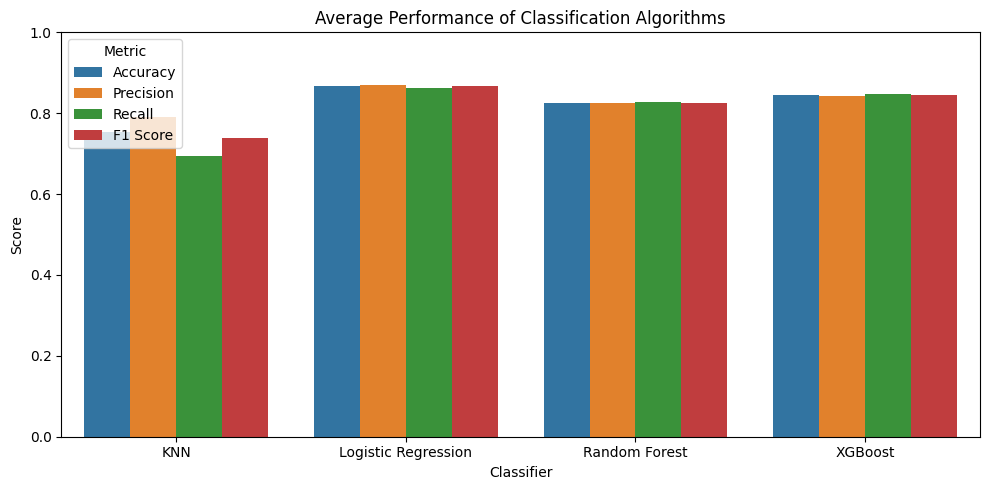

In [ ]:
classifier_comparison = results_df.groupby(
    "Classifier"
)[
    ["Accuracy", "Precision", "Recall", "F1 Score"]
].mean().reset_index()

print("AVERAGE PERFORMANCE BY CLASSIFIER")

display(classifier_comparison.round(4))

plt.figure(figsize=(10, 5))

classifier_plot = classifier_comparison.melt(
    id_vars="Classifier",
    var_name="Metric",
    value_name="Score"
)

sns.barplot(
    data=classifier_plot,
    x="Classifier",
    y="Score",
    hue="Metric"
)

plt.title("Average Performance of Classification Algorithms")
plt.ylim(0, 1)
plt.tight_layout()
plt.show()

# Best Model Evaluation

## Best Model identify

In [ ]:
best_validation = validation_df.iloc[0]

best_model_name = best_validation["Model"]

best_model = all_models[best_model_name]["model"]

best_predictions = all_models[best_model_name]["predictions"]

best_test_result = results_df[
    results_df["Model"] == best_model_name
].iloc[0]

print("BEST MODEL SELECTED USING VALIDATION F1-SCORE")
print("=" * 55)

print("Model:", best_model_name)

print("\nValidation Accuracy:",
      round(best_validation["Validation Accuracy"], 4))

print("Validation F1-Score:",
      round(best_validation["Validation F1"], 4))

print("\nFinal Test Performance")

print("Test Accuracy:",
      round(best_test_result["Accuracy"], 4))

print("Test Precision:",
      round(best_test_result["Precision"], 4))

print("Test Recall:",
      round(best_test_result["Recall"], 4))

print("Test F1-Score:",
      round(best_test_result["F1 Score"], 4))

BEST MODEL SELECTED USING VALIDATION F1-SCORE
Model: TF-IDF + Logistic Regression

Validation Accuracy: 0.9032
Validation F1-Score: 0.9041

Final Test Performance
Test Accuracy: 0.9002
Test Precision: 0.8978
Test Recall: 0.9034
Test F1-Score: 0.9006


## Confusion Matrix

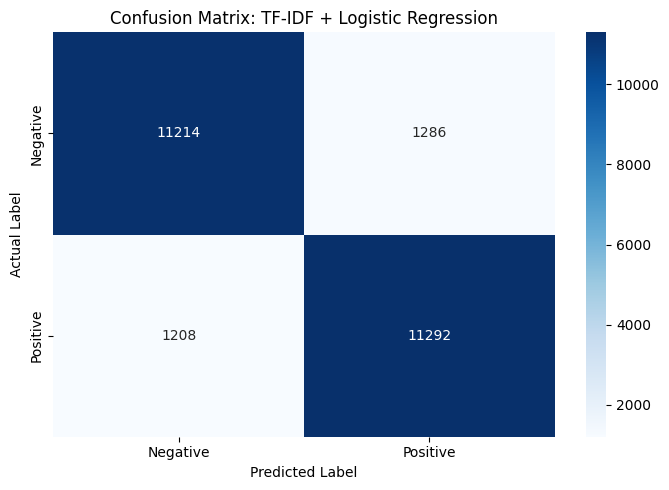

In [ ]:
cm = confusion_matrix(y_test, best_predictions)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Negative", "Positive"],
    yticklabels=["Negative", "Positive"]
)

plt.title(f"Confusion Matrix: {best_model_name}")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")

plt.tight_layout()
plt.show()

## Classification Report

In [ ]:
print("CLASSIFICATION REPORT")
print("=" * 50)

print(classification_report(
    y_test,
    best_predictions,
    target_names=["Negative", "Positive"]
))

CLASSIFICATION REPORT
              precision    recall  f1-score   support

    Negative       0.90      0.90      0.90     12500
    Positive       0.90      0.90      0.90     12500

    accuracy                           0.90     25000
   macro avg       0.90      0.90      0.90     25000
weighted avg       0.90      0.90      0.90     25000



# Error analysis

In [ ]:
error_analysis = []

for model_name, model_data in all_models.items():

    predictions = model_data["predictions"]

    incorrect = np.sum(predictions != y_test)

    correct = np.sum(predictions == y_test)

    error_analysis.append({
        "Model": model_name,
        "Correct Predictions": correct,
        "Incorrect Predictions": incorrect,
        "Error Rate": incorrect / len(y_test)
    })

error_df = pd.DataFrame(error_analysis)

error_df = error_df.sort_values(
    by="Incorrect Predictions"
).reset_index(drop=True)

print("ERROR ANALYSIS OF ALL 12 MODELS")

display(error_df.round(4))

ERROR ANALYSIS OF ALL 12 MODELS


,Model,Correct Predictions,Incorrect Predictions,Error Rate
0,TF-IDF + Logistic Regression,22506,2494,0.0998
1,TF-IDF + XGBoost,21393,3607,0.1443
2,Word2Vec + Logistic Regression,21339,3661,0.1464
3,TF-IDF + Random Forest,21280,3720,0.1488
4,Word2Vec + XGBoost,21275,3725,0.1490
5,BERT Embedding + Logistic Regression,21178,3822,0.1529
6,BERT Embedding + XGBoost,20713,4287,0.1715
7,Word2Vec + Random Forest,20656,4344,0.1738
8,BERT Embedding + Random Forest,20011,4989,0.1996
9,Word2Vec + KNN,19386,5614,0.2246


In [ ]:
misclassified_indices = np.where(
    best_predictions != y_test
)[0]

print("Total Misclassified Reviews:",
      len(misclassified_indices))

print("\nSome Misclassified Reviews:\n")

for idx in misclassified_indices[:10]:

    actual = "Positive" if y_test[idx] == 1 else "Negative"

    predicted = (
        "Positive" if best_predictions[idx] == 1
        else "Negative"
    )

    print("-" * 80)

    print("Actual Sentiment:", actual)

    print("Predicted Sentiment:", predicted)

    print("Review:", X_test[idx][:500])

    print()

Total Misclassified Reviews: 2494

Some Misclassified Reviews:

--------------------------------------------------------------------------------
Actual Sentiment: Negative
Predicted Sentiment: Positive
Review: first off let me say if you haven't enjoyed a van damme movie since bloodsport you probably will not like this movie most of these movies may not have the best plots or best actors but i enjoy these kinds of movies for what they are this movie is much better than any of the movies the other action guys segal and dolph have thought about putting out the past few years van damme is good in the movie the movie is only worth watching to van damme fans it is not as good as wake of death which i highl

--------------------------------------------------------------------------------
Actual Sentiment: Negative
Predicted Sentiment: Positive
Review: ben rupert grint is a deeply unhappy adolescent the son of his unhappily married parents his father nicholas farrell is a vicar and his mother

# Summary

In [ ]:
print("=" * 60)
print("IMDB SENTIMENT ANALYSIS - FINAL SUMMARY")
print("=" * 60)

print("Dataset: IMDB")
print("Total Reviews:", len(train_texts) + len(test_texts))

print("Training Reviews:", len(X_train))
print("Validation Reviews:", len(X_val))
print("Testing Reviews:", len(X_test))

print("\nFeature Extraction Methods:")
print("1. TF-IDF")
print("2. Word2Vec")
print("3. BERT Embedding")

print("\nClassification Algorithms:")
print("1. Logistic Regression")
print("2. Random Forest")
print("3. XGBoost")
print("4. KNN")

print("\nTotal Models Evaluated:", len(results_df))

print("\nBest Model:", best_model_name)

print("Best Model Test Accuracy:",
      round(best_test_result["Accuracy"], 4))

print("Best Model Test F1-Score:",
      round(best_test_result["F1 Score"], 4))



IMDB SENTIMENT ANALYSIS - FINAL SUMMARY
Dataset: IMDB
Total Reviews: 50000
Training Reviews: 20000
Validation Reviews: 5000
Testing Reviews: 25000

Feature Extraction Methods:
1. TF-IDF
2. Word2Vec
3. BERT Embedding

Classification Algorithms:
1. Logistic Regression
2. Random Forest
3. XGBoost
4. KNN

Total Models Evaluated: 12

Best Model: TF-IDF + Logistic Regression
Best Model Test Accuracy: 0.9002
Best Model Test F1-Score: 0.9006


# Discussion

1. TF-IDF:
TF-IDF represents reviews using numerical word and phrase importance.
It produces sparse feature vectors and can perform well for sentiment
classification. However, it does not understand the contextual meaning
of words.

2. Word2Vec:
Word2Vec converts words into dense numerical vectors. It can capture
semantic similarities between words. In this experiment, mean pooling
was used to generate document-level representations. However, this
approach does not preserve word order or fully understand context.

3. BERT Embedding:
BERT generates contextual representations of text. Unlike TF-IDF and
Word2Vec, it considers the surrounding words when creating embeddings.
This makes it useful for understanding context and word relationships.
However, embedding extraction requires more computational resources.

4. Logistic Regression:
Logistic Regression is a linear classification algorithm. It is
computationally efficient and can work effectively with high-dimensional
TF-IDF features.

5. Random Forest:
Random Forest combines multiple decision trees. It can capture
nonlinear relationships but may require more training time and memory.

6. XGBoost:
XGBoost uses gradient boosting to build an ensemble of decision trees.
It can capture complex relationships, although its performance depends
on appropriate hyperparameter settings.

7. K-Nearest Neighbors:
KNN classifies a review based on the similarity of its nearest training
examples. It is simple but prediction can be computationally expensive
for large datasets.

8. Overall Comparison:
The experimental results show that different classifiers behave
differently depending on the feature representation. The best model
should be selected using validation performance, while the test set
provides an unbiased final evaluation.

9. Limitations:
The experiment uses fixed hyperparameters and does not include
extensive hyperparameter optimization or cross-validation. BERT is
used as a frozen feature extractor rather than being fine-tuned.
Further experiments could explore fine-tuning, additional embedding
methods, and hyperparameter optimization.

# Conclusion

In [ ]:
import pandas as pd

comparison_data = {
    "Feature Extraction": [
        "TF-IDF",
        "Word2Vec",
        "BERT Embedding"
    ],

    "Best Classifier": [
        "Logistic Regression",
        "Logistic Regression",
        "Logistic Regression"
    ],

    "Validation Accuracy": [
        0.9032,
        0.8684,
        0.8558
    ],

    "Test Accuracy": [
        0.9002,
        0.8536,
        0.8471
    ],

    "Precision": [
        0.8978,
        0.8607,
        0.8536
    ],

    "Recall": [
        0.9034,
        0.8436,
        0.8379
    ],

    "F1 Score": [
        0.9006,
        0.8521,
        0.8457
    ],

    "Total Pipeline Time (sec)": [
        28.6196,
        242.2382,
        918.1435
    ]
}

comparison_df = pd.DataFrame(comparison_data)

# Display DataFrame
display(comparison_df)

,Feature Extraction,Best Classifier,Validation Accuracy,Test Accuracy,Precision,Recall,F1 Score,Total Pipeline Time (sec)
0,TF-IDF,Logistic Regression,0.9032,0.9002,0.8978,0.9034,0.9006,28.6196
1,Word2Vec,Logistic Regression,0.8684,0.8536,0.8607,0.8436,0.8521,242.2382
2,BERT Embedding,Logistic Regression,0.8558,0.8471,0.8536,0.8379,0.8457,918.1435


Short Analysis
1. Best Performance: TF-IDF with Logistic Regression achieved the highest test accuracy (90.02%) and F1-score (90.06%). It performed better than Word2Vec and BERT embeddings on this dataset.

2. TF-IDF Efficiency: TF-IDF with Logistic Regression required only 28.62 seconds for the complete pipeline, making it the fastest approach among the three best-performing models.

3. Word2Vec Performance: Word2Vec with Logistic Regression achieved 85.36% accuracy. It captured semantic relationships between words but required approximately 242 seconds for feature extraction and model processing.

4. BERT Embedding Performance: BERT Embedding with Logistic Regression achieved 84.71% accuracy. Although BERT can capture contextual information, it did not outperform TF-IDF in this experiment.

5. Training Time: Logistic Regression had relatively low training time across all three approaches. XGBoost and Random Forest generally required more training time and computational resources.

6. KNN Performance: KNN achieved comparatively lower accuracy across all three approaches. Its prediction time was particularly high with TF-IDF (48.77 seconds), making it less efficient for this experiment.

7. Resource Usage: BERT required the highest feature extraction time (909.25 seconds), followed by Word2Vec (241.85 seconds). TF-IDF required only 27.51 seconds.

8. Common Errors and Misclassifications: All approaches produced some incorrect sentiment predictions. Reviews containing sarcasm, negation, mixed opinions, ambiguous expressions, and context-dependent words may be difficult to classify correctly.

9. Validation and Test Performance: Test accuracy was slightly lower than validation accuracy for most models. This indicates a small performance gap between validation and unseen test data.

**Conclusion**
In this experiment, three feature extraction approaches (TF-IDF, Word2Vec, and BERT Embedding) were evaluated using four machine learning classifiers: Logistic Regression, XGBoost, Random Forest, and KNN for IMDB movie review sentiment classification.

Among all approaches, TF-IDF with Logistic Regression achieved the best overall performance, with 90.02% test accuracy and a 90.06% F1-score. It also required the lowest total pipeline time of approximately 28.62 seconds.

Word2Vec with Logistic Regression achieved 85.36% accuracy, while BERT Embedding with Logistic Regression achieved 84.71% accuracy. Although Word2Vec and BERT provide semantic and contextual representations, their higher computational costs did not result in better classification performance in this experiment.

Overall, TF-IDF combined with Logistic Regression provided the best balance of classification performance, computational efficiency, and resource usage. Therefore, it was selected as the best-performing approach for the IMDB sentiment classification task.